# Penerapan Algoritma Regresi untuk Memprediksi Jumlah Penyewaan Sepeda Berdasarkan Kondisi Lingkungan

**Proyek Akhir Data Science**

- Metode: Regression
- Dataset: Bike Sharing Dataset (UCI Machine Learning Repository)
- Target: `cnt` — jumlah total penyewaan sepeda
- Algoritma: Linear Regression, Decision Tree Regressor, dan Random Forest Regressor


## 1. Business Understanding

### 1.1 Latar belakang
Sistem penyewaan sepeda dapat dipengaruhi oleh waktu, musim, dan kondisi lingkungan seperti temperatur, kelembapan, kecepatan angin, serta kondisi cuaca. Prediksi jumlah penyewaan dapat membantu pengelola memperkirakan kebutuhan sepeda pada waktu tertentu.

### 1.2 Rumusan masalah
1. Bagaimana hubungan faktor waktu dan kondisi lingkungan dengan jumlah penyewaan sepeda?
2. Seberapa baik algoritma regresi memprediksi jumlah penyewaan sepeda?
3. Algoritma mana yang memberikan hasil prediksi terbaik berdasarkan MAE, RMSE, dan R²?

### 1.3 Tujuan
- Memahami pola penyewaan sepeda melalui EDA.
- Melakukan pemeriksaan dan preprocessing data.
- Melatih dan membandingkan beberapa algoritma regresi.
- Menentukan model terbaik berdasarkan data pengujian.

### 1.4 Metode dan metrik
Model yang dibandingkan adalah Linear Regression, Decision Tree Regressor, dan Random Forest Regressor. Evaluasi menggunakan:
- **MAE**: rata-rata selisih absolut prediksi dan nilai aktual; makin kecil makin baik.
- **RMSE**: akar rata-rata kuadrat kesalahan; makin kecil makin baik dan lebih sensitif terhadap kesalahan besar.
- **R²**: proporsi variasi target yang dijelaskan model; umumnya makin mendekati 1 makin baik.

Pembagian data dilakukan berdasarkan urutan tanggal: data lebih awal digunakan untuk pelatihan dan data lebih akhir untuk pengujian. Pendekatan ini lebih realistis untuk data yang memiliki urutan waktu.

## 2. Data Gathering

Dataset diambil dari UCI Machine Learning Repository.

- **Sumber:** https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset
- **Penulis dataset:** Hadi Fanaee-T
- **Periode:** 2011–2012
- **Unit observasi:** jumlah penyewaan sepeda per jam
- **Lisensi:** Creative Commons Attribution 4.0 International (CC BY 4.0)
- **Sitasi:** Fanaee-T, H. (2013). *Bike Sharing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894

File `hour.csv` dipilih karena berisi pengamatan per jam sehingga dapat dianalisis berdasarkan jam, cuaca, dan faktor waktu.

### Deskripsi kolom yang digunakan
- `season`: musim
- `yr`: tahun (0 = 2011, 1 = 2012)
- `mnth`: bulan
- `hr`: jam
- `holiday`: indikator hari libur
- `weekday`: hari dalam minggu
- `workingday`: indikator hari kerja
- `weathersit`: kategori kondisi cuaca
- `temp`: temperatur yang telah dinormalisasi
- `atemp`: temperatur terasa yang telah dinormalisasi
- `hum`: kelembapan yang telah dinormalisasi
- `windspeed`: kecepatan angin yang telah dinormalisasi
- `cnt`: jumlah total penyewaan sepeda (target)

Kolom `casual` dan `registered` tidak digunakan sebagai fitur karena `cnt` merupakan jumlah dari kedua kolom tersebut. Menggunakannya akan menyebabkan **target leakage**. Kolom ID `instant` juga tidak digunakan sebagai prediktor.

In [37]:
import os
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

In [38]:

import os
import urllib.request
import zipfile
import pandas as pd

# URL dataset resmi UCI
zip_url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

# Simpan dataset di folder kerja saat ini
zip_path = "bike_sharing_dataset.zip"
extract_dir = "bike_sharing_dataset"

# Unduh dataset jika belum tersedia
if not os.path.exists(zip_path):
    print("Mengunduh dataset...")
    urllib.request.urlretrieve(zip_url, zip_path)

# Ekstrak dataset
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

# Baca file CSV
csv_path = os.path.join(extract_dir, "hour.csv")
df = pd.read_csv(csv_path)

print("Dataset berhasil dimuat.")
print("Ukuran dataset:", df.shape)
display(df.head())


Mengunduh dataset...
Dataset berhasil dimuat.
Ukuran dataset: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### 2.1 Pemeriksaan awal
Periksa bentuk dataset, nama kolom, tipe data, dan contoh data untuk memastikan file terbaca dengan benar.

In [39]:
print("Jumlah baris dan kolom:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nTipe data:")
display(df.dtypes.to_frame("dtype"))

print("\nInformasi dataset:")
df.info()

Jumlah baris dan kolom: (17379, 17)

Nama kolom:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Tipe data:


,dtype
instant,int64
dteday,str
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64



Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


## 3. Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami distribusi target, pola penyewaan berdasarkan waktu, hubungan faktor lingkungan dengan target, dan kualitas data. Setiap grafik perlu dijelaskan berdasarkan hasil yang muncul ketika notebook dijalankan.

In [40]:
# Statistik deskriptif untuk kolom numerik
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


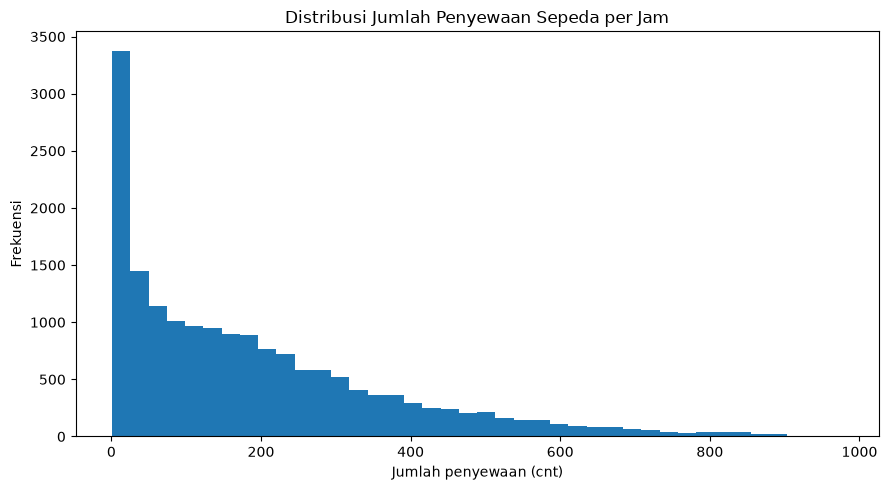

In [41]:
# Distribusi jumlah penyewaan sepeda
plt.figure(figsize=(9, 5))
plt.hist(df["cnt"], bins=40)
plt.title("Distribusi Jumlah Penyewaan Sepeda per Jam")
plt.xlabel("Jumlah penyewaan (cnt)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

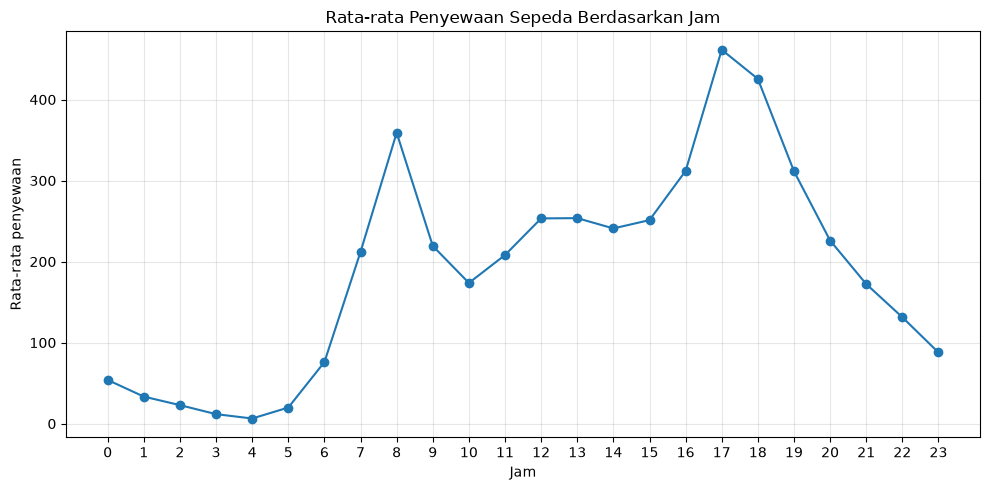

In [42]:
# Rata-rata penyewaan berdasarkan jam
hourly_avg = df.groupby("hr", as_index=False)["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_avg["hr"], hourly_avg["cnt"], marker="o")
plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata penyewaan")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

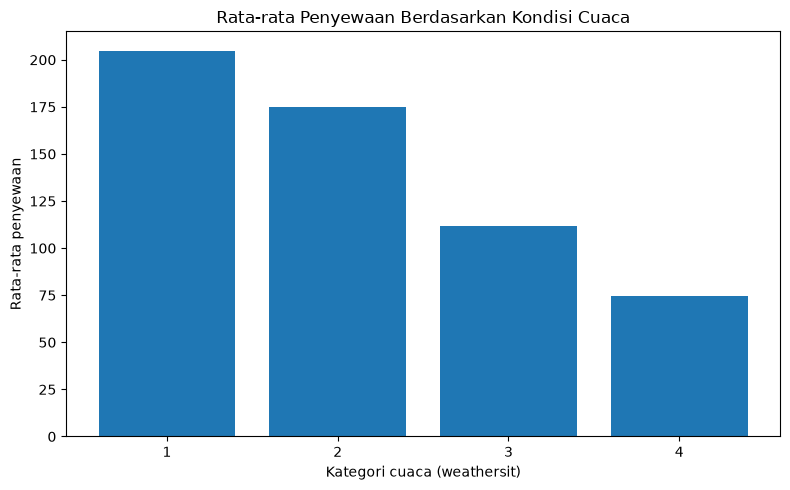

In [43]:
# Rata-rata penyewaan berdasarkan kondisi cuaca
weather_avg = df.groupby("weathersit", as_index=False)["cnt"].mean()

plt.figure(figsize=(8, 5))
plt.bar(weather_avg["weathersit"].astype(str), weather_avg["cnt"])
plt.title("Rata-rata Penyewaan Berdasarkan Kondisi Cuaca")
plt.xlabel("Kategori cuaca (weathersit)")
plt.ylabel("Rata-rata penyewaan")
plt.tight_layout()
plt.show()

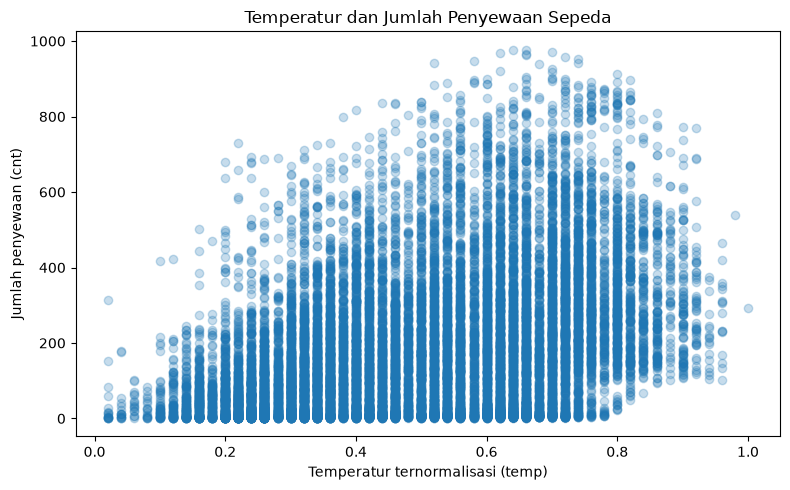

In [44]:
# Hubungan temperatur dengan jumlah penyewaan
plt.figure(figsize=(8, 5))
plt.scatter(df["temp"], df["cnt"], alpha=0.25)
plt.title("Temperatur dan Jumlah Penyewaan Sepeda")
plt.xlabel("Temperatur ternormalisasi (temp)")
plt.ylabel("Jumlah penyewaan (cnt)")
plt.tight_layout()
plt.show()

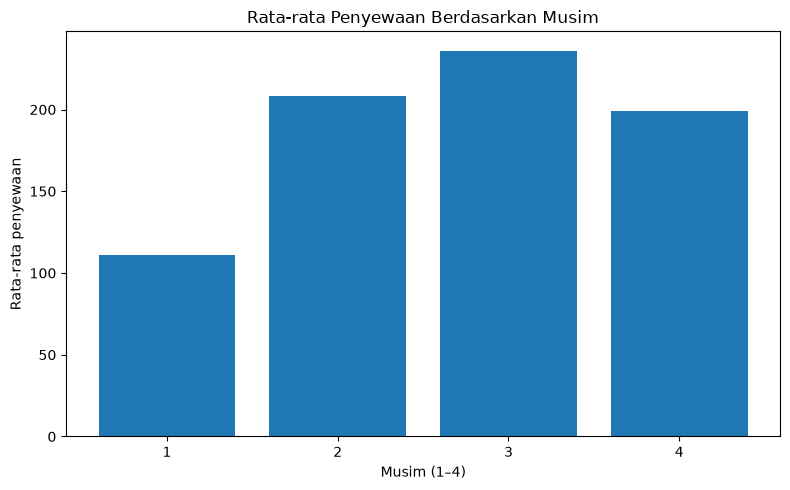

In [45]:
# Rata-rata penyewaan berdasarkan musim
season_avg = df.groupby("season", as_index=False)["cnt"].mean()

plt.figure(figsize=(8, 5))
plt.bar(season_avg["season"].astype(str), season_avg["cnt"])
plt.title("Rata-rata Penyewaan Berdasarkan Musim")
plt.xlabel("Musim (1–4)")
plt.ylabel("Rata-rata penyewaan")
plt.tight_layout()
plt.show()

## 4. Cleaning dan Preprocessing

Tahap ini memeriksa missing value, duplikat, tipe data, dan kemungkinan outlier. Dataset UCI ini didokumentasikan tidak memiliki missing value, tetapi pemeriksaan tetap dilakukan sebagai bagian dari prosedur kualitas data.

Outlier tidak langsung dihapus: nilai ekstrem pada jumlah penyewaan bisa merupakan kejadian yang valid. Hasil pemeriksaan perlu didiskusikan sebelum memutuskan penanganannya.

In [46]:
# 4.1 Missing values
missing_counts = df.isna().sum().sort_values(ascending=False)
display(missing_counts.to_frame("missing_count"))

print("Total missing value:", int(df.isna().sum().sum()))

,missing_count
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Total missing value: 0


In [47]:
# 4.2 Duplikat
duplicate_count = int(df.duplicated().sum())
print("Jumlah baris duplikat:", duplicate_count)

# Hapus hanya jika ada baris yang benar-benar identik.
df_clean = df.drop_duplicates().copy()
print("Ukuran sebelum:", df.shape)
print("Ukuran setelah drop_duplicates:", df_clean.shape)

Jumlah baris duplikat: 0
Ukuran sebelum: (17379, 17)
Ukuran setelah drop_duplicates: (17379, 17)


In [48]:
# 4.3 Periksa rentang dan tipe data
display(df_clean[["temp", "atemp", "hum", "windspeed", "cnt"]].describe().T)
print("Tipe data dteday sebelum konversi:", df_clean["dteday"].dtype)

df_clean["dteday"] = pd.to_datetime(df_clean["dteday"], errors="coerce")
print("Jumlah tanggal yang gagal dikonversi:", int(df_clean["dteday"].isna().sum()))

,count,mean,std,min,25%,50%,75%,max
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000
atemp,17379.0,0.475775,0.171850,0.00,0.3333,0.4848,0.6212,1.0000
hum,17379.0,0.627229,0.192930,0.00,0.4800,0.6300,0.7800,1.0000
windspeed,17379.0,0.190098,0.122340,0.00,0.1045,0.1940,0.2537,0.8507
cnt,17379.0,189.463088,181.387599,1.00,40.0000,142.0000,281.0000,977.0000


Tipe data dteday sebelum konversi: str
Jumlah tanggal yang gagal dikonversi: 0


In [49]:
# 4.4 Deteksi outlier dengan aturan IQR pada beberapa kolom numerik
# Ini hanya menghitung kandidat outlier, bukan langsung menghapusnya.
outlier_summary = []
for col in ["temp", "atemp", "hum", "windspeed", "cnt"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = int(((df_clean[col] < lower) | (df_clean[col] > upper)).sum())
    outlier_summary.append({
        "kolom": col,
        "batas_bawah_IQR": lower,
        "batas_atas_IQR": upper,
        "jumlah_kandidat_outlier": n_outliers
    })

display(pd.DataFrame(outlier_summary))

,kolom,batas_bawah_IQR,batas_atas_IQR,jumlah_kandidat_outlier
0,temp,-0.14000,1.14000,0
1,atemp,-0.09855,1.05305,0
2,hum,0.03000,1.23000,22
3,windspeed,-0.11930,0.47750,342
4,cnt,-321.50000,642.50000,505


### Keputusan cleaning
- Missing value diperiksa dan jumlahnya dilaporkan.
- Baris duplikat identik dihapus jika ditemukan.
- Tanggal dikonversi ke format datetime untuk membantu pengurutan data.
- Kandidat outlier ditandai dengan aturan IQR. Nilai ekstrem tidak otomatis dihapus karena bisa menggambarkan kondisi permintaan yang nyata.
- `instant`, `dteday`, `casual`, dan `registered` tidak dipakai sebagai fitur model. `instant` adalah ID, `dteday` digunakan untuk pengurutan kronologis, sedangkan `casual` dan `registered` menimbulkan target leakage untuk target `cnt`.

## 5. Modelling

### 5.1 Pemilihan fitur
Fitur yang digunakan mencakup faktor waktu, cuaca, dan lingkungan. `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday`, dan `weathersit` diperlakukan sebagai kategori. Variabel temperatur, kelembapan, dan kecepatan angin diperlakukan sebagai numerik.

`temp` dan `atemp` mungkin berkorelasi kuat; keduanya tetap disertakan pada eksperimen awal, tetapi hal ini dapat dibahas sebagai keterbatasan interpretasi Linear Regression.

In [50]:
categorical_features = [
    "season", "yr", "mnth", "hr", "holiday",
    "weekday", "workingday", "weathersit"
]
numeric_features = ["temp", "atemp", "hum", "windspeed"]
feature_cols = categorical_features + numeric_features
target_col = "cnt"

# Buat data untuk modelling dan urutkan berdasarkan tanggal.
model_df = df_clean.dropna(subset=["dteday"]).sort_values("dteday").reset_index(drop=True)

X = model_df[feature_cols]
y = model_df[target_col]

# Split kronologis: 80% awal untuk train, 20% akhir untuk test.
split_index = int(len(model_df) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Jumlah data train:", len(X_train))
print("Jumlah data test:", len(X_test))
print("Rentang tanggal train:", model_df["dteday"].iloc[0], "sampai", model_df["dteday"].iloc[split_index - 1])
print("Rentang tanggal test:", model_df["dteday"].iloc[split_index], "sampai", model_df["dteday"].iloc[-1])

Jumlah data train: 13903
Jumlah data test: 3476
Rentang tanggal train: 2011-01-01 00:00:00 sampai 2012-08-07 00:00:00
Rentang tanggal test: 2012-08-07 00:00:00 sampai 2012-12-31 00:00:00


In [51]:
# Preprocessing: imputasi median untuk numerik dan modus untuk kategori,
# kemudian One-Hot Encoding untuk kategori.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(
        random_state=RANDOM_STATE,
        min_samples_leaf=5
    ),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=150,
        random_state=RANDOM_STATE,
        min_samples_leaf=2,
        n_jobs=-1
    )
}

fitted_models = {}
predictions = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    fitted_models[name] = pipe
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df)

,Model,MAE,RMSE,R2
0,Random Forest Regressor,55.643311,83.474610,0.856376
1,Decision Tree Regressor,63.963167,99.599288,0.795530
2,Linear Regression,98.822302,133.650822,0.631819


## 6. Evaluation

Gunakan tabel hasil evaluasi di atas untuk membandingkan model pada data pengujian yang sama. Model dengan MAE dan RMSE lebih kecil serta R² lebih tinggi biasanya lebih baik, tetapi hasil harus dibaca bersama konteks data dan pola kesalahan.

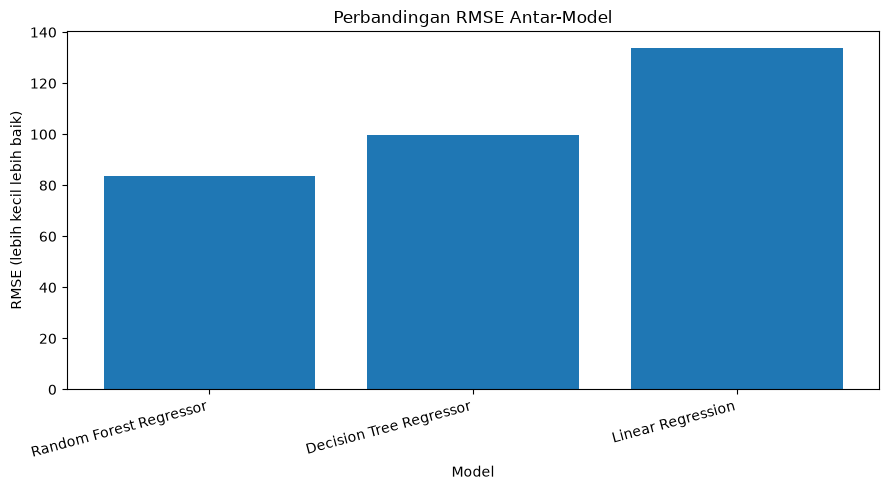

In [52]:
# Grafik perbandingan RMSE
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Perbandingan RMSE Antar-Model")
plt.xlabel("Model")
plt.ylabel("RMSE (lebih kecil lebih baik)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Model terbaik berdasarkan RMSE: Random Forest Regressor


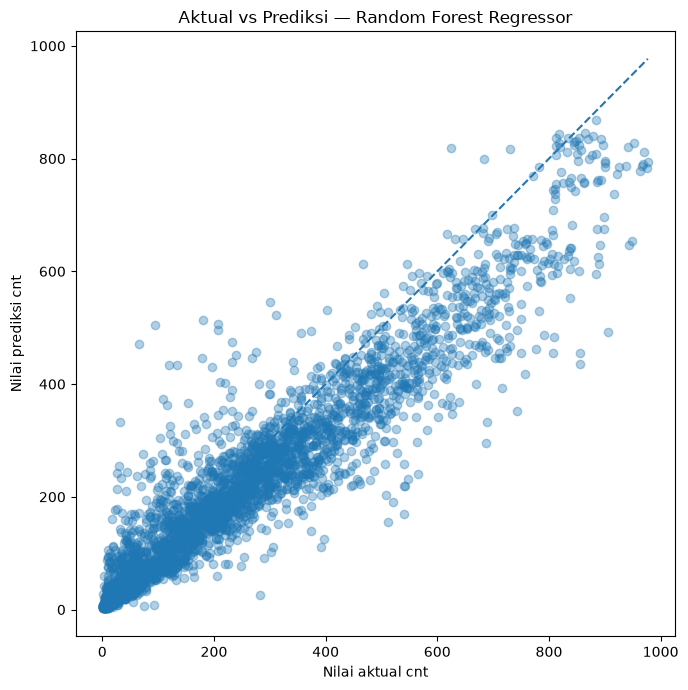

In [53]:
# Grafik nilai aktual vs prediksi dari model dengan RMSE terkecil
best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

print("Model terbaik berdasarkan RMSE:", best_model_name)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_predictions, alpha=0.35)
min_val = min(float(np.min(y_test)), float(np.min(best_predictions)))
max_val = max(float(np.max(y_test)), float(np.max(best_predictions)))
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.title(f"Aktual vs Prediksi — {best_model_name}")
plt.xlabel("Nilai aktual cnt")
plt.ylabel("Nilai prediksi cnt")
plt.tight_layout()
plt.show()

In [54]:
# Ringkasan metrik model terbaik
best_row = results_df.iloc[0]
print(f"Model terbaik berdasarkan RMSE: {best_row['Model']}")
print(f"MAE  : {best_row['MAE']:.3f}")
print(f"RMSE : {best_row['RMSE']:.3f}")
print(f"R²   : {best_row['R2']:.3f}")

Model terbaik berdasarkan RMSE: Random Forest Regressor
MAE  : 55.643
RMSE : 83.475
R²   : 0.856


In [55]:

print("Total missing value:", df.isnull().sum().sum())
print("Jumlah baris duplikat:", df.duplicated().sum())

print("\nMissing value setiap kolom:")
print(df.isnull().sum())


kolom_numerik = ["temp", "atemp", "hum", "windspeed", "cnt"]

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    print(f"{kolom}: {jumlah_outlier} kandidat outlier")


print("Rata-rata penyewaan berdasarkan jam:")
print(df.groupby("hr")["cnt"].mean().round(2))

print("\nRata-rata penyewaan berdasarkan musim:")
print(df.groupby("season")["cnt"].mean().round(2))

print("\nKorelasi fitur numerik dengan jumlah penyewaan:")
print(df.corr(numeric_only=True)["cnt"].sort_values(ascending=False))


Total missing value: 0
Jumlah baris duplikat: 0

Missing value setiap kolom:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
temp: 0 kandidat outlier
atemp: 0 kandidat outlier
hum: 22 kandidat outlier
windspeed: 342 kandidat outlier
cnt: 505 kandidat outlier
Rata-rata penyewaan berdasarkan jam:
hr
0      53.90
1      33.38
2      22.87
3      11.73
4       6.35
5      19.89
6      76.04
7     212.06
8     359.01
9     219.31
10    173.67
11    208.14
12    253.32
13    253.66
14    240.95
15    251.23
16    311.98
17    461.45
18    425.51
19    311.52
20    226.03
21    172.31
22    131.34
23     87.83
Name: cnt, dtype: float64

Rata-rata penyewaan berdasarkan musim:
season
1    111.11
2    208.34
3    236.02
4    198.87
Name: cnt, dtype: float64

Kore




## 7. Conclusion

Berdasarkan eksperimen pada *Bike Sharing Dataset*, penelitian ini membandingkan algoritma Linear Regression, Decision Tree Regressor, dan Random Forest Regressor untuk memprediksi jumlah penyewaan sepeda (`cnt`) berdasarkan faktor waktu dan lingkungan. Hasil evaluasi menunjukkan bahwa **Random Forest Regressor merupakan model terbaik berdasarkan nilai RMSE**, dengan nilai MAE sebesar **55,643**, RMSE sebesar **83,475**, dan R² sebesar **0,856** pada data pengujian.

Nilai MAE menunjukkan bahwa rata-rata selisih absolut antara jumlah penyewaan sepeda aktual dan hasil prediksi adalah sekitar 55,643 penyewaan per observasi. Nilai RMSE sebesar 83,475 menunjukkan besarnya kesalahan prediksi dengan penalti lebih besar terhadap kesalahan yang tinggi. Sementara itu, nilai R² sebesar 0,856 menunjukkan bahwa model dapat menjelaskan sekitar **85,6% variasi jumlah penyewaan sepeda pada data pengujian**. Hasil ini menunjukkan bahwa Random Forest Regressor memiliki kemampuan prediksi yang baik pada data yang digunakan.

Hasil Exploratory Data Analysis (EDA) menunjukkan bahwa jumlah penyewaan sepeda memiliki hubungan dengan beberapa faktor waktu dan lingkungan. Berdasarkan analisis korelasi, variabel kelembapan (`hum`) memiliki korelasi negatif sebesar -0,323 terhadap jumlah penyewaan sepeda (`cnt`), sedangkan kondisi cuaca (`weathersit`) memiliki korelasi negatif sebesar -0,142. Hal ini menunjukkan bahwa peningkatan kelembapan dan kondisi cuaca yang kurang baik cenderung berkaitan dengan penurunan jumlah penyewaan sepeda.

Pemeriksaan kualitas data menemukan **0 missing value** dan **0 baris duplikat**. Berdasarkan metode Interquartile Range (IQR), ditemukan **22 kandidat outlier pada variabel kelembapan (`hum`)**, sedangkan variabel temperatur (`temp`) dan temperatur terasa (`atemp`) tidak menunjukkan kandidat outlier. Kandidat outlier tidak dihapus secara otomatis karena nilai ekstrem dapat merepresentasikan kondisi lingkungan yang valid.


Keterbatasan penelitian ini meliputi cakupan data yang terbatas pada Washington, D.C. selama periode 2011–2012, kemungkinan perubahan pola permintaan dari waktu ke waktu, serta keterbatasan fitur yang tersedia dalam dataset. Oleh karena itu, model perlu diuji lebih lanjut menggunakan data dari periode atau wilayah lain sebelum diterapkan dalam kondisi nyata.


## Referensi

Fanaee-T, H. (2013). *Bike Sharing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894

UCI Machine Learning Repository. *Bike Sharing Dataset*. https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

